# ML Zoomcamp 2026 - Homework 4
Evaluation Metrics for Classification (pinned 2026 lead-scoring release)

Note: this homework uses `random_state=1` for the splits (HW3 used `42`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

## Data preparation

In [2]:
!wget -q -nc https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

df = pd.read_csv('course_lead_scoring_2026.csv')
df.shape  # (5000, 9)

(5000, 9)

In [3]:
df.isnull().sum()
# lead_source 148 | industry 240 | employment_status 194 | location 208
# annual_income 369 | lead_score 35 | others 0

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [4]:
categorical = list(df.dtypes[df.dtypes == 'object'].index)
numerical = [c for c in df.columns if c not in categorical + ['converted']]

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

categorical, numerical

(['lead_source', 'industry', 'employment_status', 'location'],
 ['annual_income',
  'number_of_courses_viewed',
  'interaction_count',
  'lead_score'])

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

len(df_train), len(df_val), len(df_test)  # 3000, 1000, 1000

(3000, 1000, 1000)

## Q1. ROC AUC feature importance

In [6]:
for c in numerical:
    auc = roc_auc_score(y_train, df_train[c])
    auc_inv = roc_auc_score(y_train, -df_train[c])
    print(f'{c:26s} auc={auc:.4f}  inverted={auc_inv:.4f}  best={max(auc, auc_inv):.3f}')

# annual_income             0.608
# number_of_courses_viewed  0.723
# interaction_count         0.765
# lead_score                0.788   <-- highest (not inverted: all are > 0.5)

annual_income              auc=0.6082  inverted=0.3918  best=0.608
number_of_courses_viewed   auc=0.7230  inverted=0.2770  best=0.723
interaction_count          auc=0.7649  inverted=0.2351  best=0.765
lead_score                 auc=0.7882  inverted=0.2118  best=0.788


## Q2. Train the model

In [7]:
features = categorical + numerical

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
X_val = dv.transform(df_val[features].to_dict(orient='records'))

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
auc, round(auc, 3)   # 0.73182 -> 0.732

(0.7318222288173319, 0.732)

## Q3. Precision and recall

In [8]:
thresholds = np.arange(0.0, 1.0, 0.01)

scores = []
for t in thresholds:
    y_hat = (y_pred >= t).astype(int)
    p = precision_score(y_val, y_hat, zero_division=0)
    r = recall_score(y_val, y_hat, zero_division=0)
    scores.append((t, p, r))

df_scores = pd.DataFrame(scores, columns=['threshold', 'precision', 'recall'])
df_scores.head()

,threshold,precision,recall
0,0.00,0.586,1.0
1,0.01,0.586,1.0
2,0.02,0.586,1.0
3,0.03,0.586,1.0
4,0.04,0.586,1.0


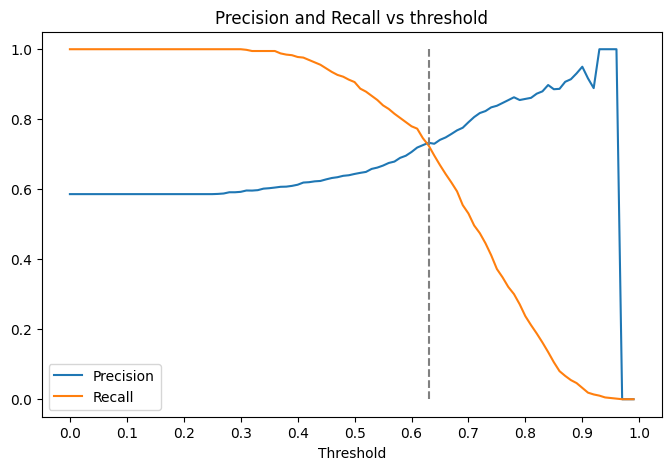

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.vlines(0.63, 0, 1, colors='grey', linestyles='dashed')
plt.xticks(np.arange(0, 1.01, 0.1))
plt.xlabel('Threshold')
plt.legend()
plt.title('Precision and Recall vs threshold')
plt.show()

In [10]:
# ignore thresholds where BOTH metrics are zero, then take the smallest |P - R|
d = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
d['diff'] = (d.precision - d.recall).abs()
d.sort_values(['diff', 'threshold']).head()

# threshold  precision  recall   diff
# 0.63       0.7328     0.7253   0.0075   <-- smallest
# 0.62       0.7259     0.7457   0.0198
# 0.64       0.7299     0.6962   0.0336

,threshold,precision,recall,diff
63,0.63,0.732759,0.725256,0.007503
62,0.62,0.725914,0.745734,0.019820
64,0.64,0.729875,0.696246,0.033629
61,0.61,0.719048,0.773038,0.053990
65,0.65,0.741021,0.668942,0.072079


## Q4. F1 score

In [11]:
df_scores['f1'] = (2 * df_scores.precision * df_scores.recall
                   / (df_scores.precision + df_scores.recall))
df_scores = df_scores.fillna(0)

df_scores.sort_values('f1', ascending=False).head()

# threshold  precision  recall   f1
# 0.41       0.6190     0.9761   0.7576   <-- maximal
# 0.42       0.6201     0.9693   0.7563
# 0.43       0.6225     0.9625   0.7560

,threshold,precision,recall,f1
41,0.41,0.619048,0.976109,0.757616
42,0.42,0.620087,0.969283,0.756325
43,0.43,0.622517,0.962457,0.756032
45,0.45,0.628118,0.945392,0.754768
44,0.44,0.623608,0.955631,0.754717


In [12]:
df_scores.loc[df_scores.f1.idxmax(), 'threshold']   # 0.41

0.41000000000000003

## Q5. 5-Fold CV

In [13]:
def train(df_tr, y_tr, C=1.0):
    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(df_tr[features].to_dict(orient='records'))
    m = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    m.fit(X_tr, y_tr)
    return dv, m


def predict(df_x, dv, m):
    X = dv.transform(df_x[features].to_dict(orient='records'))
    return m.predict_proba(X)[:, 1]


kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_tr = df_full_train.iloc[train_idx]
    df_va = df_full_train.iloc[val_idx]

    dv, m = train(df_tr, df_tr.converted.values)
    scores.append(roc_auc_score(df_va.converted.values, predict(df_va, dv, m)))

print([round(s, 4) for s in scores])
# [0.7306, 0.7296, 0.7363, 0.7412, 0.7209]

np.mean(scores), np.std(scores), round(np.std(scores), 3)   # 0.7317, 0.00685 -> 0.007

[0.7306, 0.7296, 0.7363, 0.7412, 0.7209]


(0.7317269710972524, 0.006853233151022138, 0.007)

## Q6. Hyperparameter tuning

In [14]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    s = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_va = df_full_train.iloc[val_idx]

        dv, m = train(df_tr, df_tr.converted.values, C)
        s.append(roc_auc_score(df_va.converted.values, predict(df_va, dv, m)))

    print(f'C={C:<10} mean={round(np.mean(s), 3)}  std={round(np.std(s), 3)}')

# C=1e-06       mean=0.617  std=0.019
# C=0.001       mean=0.749  std=0.010   <-- best mean AUC
# C=1           mean=0.732  std=0.007

C=1e-06      mean=0.617  std=0.019
C=0.001      mean=0.749  std=0.01
C=1          mean=0.732  std=0.007


## Answers
| Q | Question | Answer |
|---|---|---|
| 1 | Highest AUC (numerical) | `lead_score` (0.788) |
| 2 | Validation AUC | 0.732 |
| 3 | Precision/recall intersection | 0.63 |
| 4 | Max F1 | 0.41 |
| 5 | Std of 5-fold CV scores | 0.007 |
| 6 | Best `C` | 0.001 (mean 0.749) |

**Worth noticing:** the best `C` on validation AUC (`0.001`) is *not* the default `C=1.0`, and
the gap is real: 0.749 vs 0.732. This is the same finding as HW3, where `C=0.001` also won - the
unscaled `annual_income` column needs a tighter penalty to stop it from dominating. Regularization
is doing real work here, not just rounding noise.

Also note the F1-optimal threshold (0.41) is far below the precision/recall crossover (0.63). F1
prefers to catch almost every conversion (recall 0.976) at the cost of precision (0.619). Which
threshold you actually ship depends on whether a false positive or a missed lead costs you more -
F1 silently assumes they cost the same.